# MLOps completo — Previsão de preços de casas na Califórnia

Este notebook implementa um ciclo MLOps usando o dataset **California Housing** do `scikit-learn`:

1. Coleta e validação dos dados  
2. Análise de valores nulos e outliers (IQR)  
3. Associação das features com o alvo (Spearman e Mutual Information)  
4. Engenharia, normalização e padronização de features  
5. Divisão treino/teste e treinamento de uma regressão Ridge  
6. Avaliação com MAE, MSE, RMSE e MAPE  
7. Rastreabilidade e versionamento do modelo com **MLflow**  
8. Geração de uma interface funcional em **Streamlit**, exibindo a versão registrada do modelo  

> **Observação:** na primeira execução, `fetch_california_housing()` pode baixar os dados. O target está expresso em centenas de milhares de dólares.


## 0. Instalação de dependências

Execute esta célula uma vez, se necessário. Depois reinicie o kernel caso o ambiente solicite.


In [1]:
# !pip install -q scikit-learn pandas numpy matplotlib seaborn scipy mlflow streamlit

## 1. Imports e configuração

In [2]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import spearmanr
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.feature_selection import mutual_info_regression
from sklearn.inspection import permutation_importance

import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

PROJECT_DIR = Path.cwd() / "california_housing_mlops"
PROJECT_DIR.mkdir(exist_ok=True)
MLRUNS_DIR = PROJECT_DIR / "mlruns"
MLRUNS_DIR.mkdir(exist_ok=True)

# Tracking local usando SQLite
MLFLOW_DB = PROJECT_DIR / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{MLFLOW_DB.resolve().as_posix()}")

# Cria ou seleciona o experimento
mlflow.set_experiment("CaliforniaHousingRidgeExperiment")

print(f"Projeto: {PROJECT_DIR}")
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Banco de dados: {MLFLOW_DB.resolve()}")

print(f"Projeto: {PROJECT_DIR}")
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")

Projeto: C:\Users\Administrator\Documents\FGV\MLOps e Versionamento\california_housing_mlops
MLflow Tracking URI: sqlite:///C:/Users/Administrator/Documents/FGV/MLOps e Versionamento/california_housing_mlops/mlflow.db
Banco de dados: C:\Users\Administrator\Documents\FGV\MLOps e Versionamento\california_housing_mlops\mlflow.db
Projeto: C:\Users\Administrator\Documents\FGV\MLOps e Versionamento\california_housing_mlops
MLflow Tracking URI: sqlite:///C:/Users/Administrator/Documents/FGV/MLOps e Versionamento/california_housing_mlops/mlflow.db


## 2. Carregamento da base California Housing

In [3]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

TARGET = "MedHouseVal"
print(f"Formato: {df.shape}")
display(df.head())
display(df.describe().T)

Formato: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


## 3. Verificação de qualidade dos dados

### 3.1 Valores nulos


In [4]:
null_report = (
    df.isna()
      .sum()
      .rename("nulos")
      .to_frame()
      .assign(percentual=lambda x: 100 * x["nulos"] / len(df))
)
display(null_report)

if null_report["nulos"].sum() == 0:
    print("Não foram encontrados valores nulos.")
else:
    print("Há valores nulos; o pipeline contém imputação para lidar com eles.")

,nulos,percentual
MedInc,0,0.0
HouseAge,0,0.0
AveRooms,0,0.0
AveBedrms,0,0.0
Population,0,0.0
AveOccup,0,0.0
Latitude,0,0.0
Longitude,0,0.0
MedHouseVal,0,0.0


Não foram encontrados valores nulos.


### 3.2 Outliers pelo método IQR

Para cada coluna numérica:
- limite inferior = Q1 − 1,5 × IQR
- limite superior = Q3 + 1,5 × IQR

Abaixo é apresentado o número de observações fora desses limites. A identificação não implica remoção automática: em preços e variáveis socioeconômicas, extremos podem conter sinal relevante.


,feature,q1,q3,iqr,limite_inferior,limite_superior,n_outliers,pct_outliers
3,AveBedrms,1.006,1.100,0.093,0.866,1.240,1424,6.90%
4,Population,787.000,1725.000,938.000,-620.000,3132.000,1196,5.79%
8,MedHouseVal,1.196,2.647,1.451,-0.981,4.824,1071,5.19%
5,AveOccup,2.430,3.282,0.853,1.151,4.561,711,3.44%
0,MedInc,2.563,4.743,2.180,-0.706,8.013,681,3.30%
2,AveRooms,4.441,6.052,1.612,2.023,8.470,511,2.48%
1,HouseAge,18.000,37.000,19.000,-10.500,65.500,0,0.00%
6,Latitude,33.930,37.710,3.780,28.260,43.380,0,0.00%
7,Longitude,-121.800,-118.010,3.790,-127.485,-112.325,0,0.00%


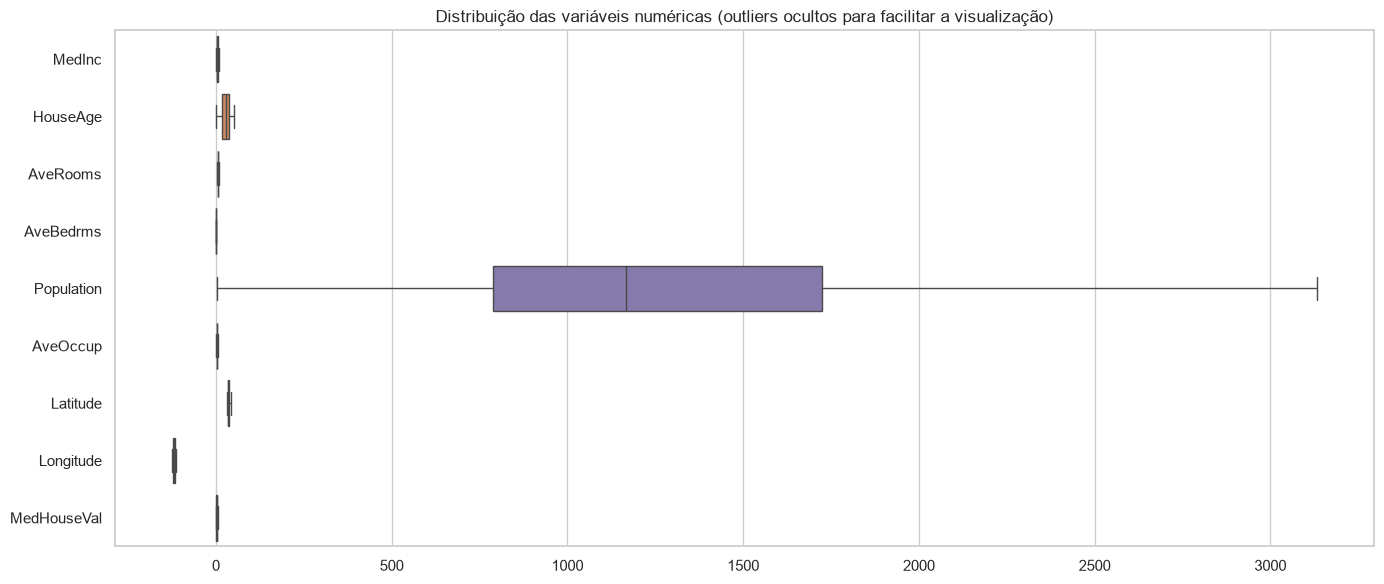

In [5]:
numeric_original_cols = df.select_dtypes(include=np.number).columns.tolist()

outlier_rows = []
for col in numeric_original_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_rows.append({
        "feature": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "limite_inferior": lower,
        "limite_superior": upper,
        "n_outliers": int(count),
        "pct_outliers": 100 * count / len(df),
    })

outlier_report = pd.DataFrame(outlier_rows).sort_values("n_outliers", ascending=False)
display(outlier_report.style.format({
    "q1": "{:.3f}", "q3": "{:.3f}", "iqr": "{:.3f}",
    "limite_inferior": "{:.3f}", "limite_superior": "{:.3f}",
    "pct_outliers": "{:.2f}%"
}))

plt.figure(figsize=(14, 6))
sns.boxplot(data=df[numeric_original_cols], orient="h", showfliers=False)
plt.title("Distribuição das variáveis numéricas (outliers ocultos para facilitar a visualização)")
plt.tight_layout()
plt.show()

## 4. Engenharia de atributos

O dataset original não possui colunas categóricas. Para demonstrar o fluxo de *one-hot encoding* e a análise de Mutual Information, criamos `IncomeCategory`, uma categoria interpretável baseada em faixas de renda mediana. Também são criadas razões demográficas e uma transformação logarítmica da renda.

> As variáveis derivadas são obtidas apenas de features de entrada e não usam o target.


In [ ]:
data = df.copy()

# Razões com denominador protegido contra zero.
data["RoomsPerHousehold"] = data["AveRooms"] / data["AveOccup"].clip(lower=0.1)
data["BedroomsPerRoom"] = data["AveBedrms"] / data["AveRooms"].clip(lower=0.1)
data["PopulationPerHousehold"] = data["Population"] / data["AveOccup"].clip(lower=0.1)
data["MedIncLog"] = np.log1p(data["MedInc"])

# Faixas de renda (feature categórica para one-hot e MI).
data["IncomeCategory"] = pd.cut(
    data["MedInc"],
    bins=[-np.inf, 2, 4, 6, np.inf],
    labels=["Baixa", "Média-baixa", "Média-alta", "Alta"]
).astype("object")

original_feature_cols = [c for c in df.columns if c != TARGET]
continuous_cols = original_feature_cols + [
    "RoomsPerHousehold", "BedroomsPerRoom", "PopulationPerHousehold", "MedIncLog"
]
categorical_cols = ["IncomeCategory"]

display(data.head())
print("Features contínuas:", continuous_cols)
print("Features categóricas:", categorical_cols)

## 5. Estudo de associação com o target

- **Spearman** para target contínuo × features contínuas: avalia associação monotônica.
- **Mutual Information** para feature categórica × target contínuo: mede dependência, inclusive não linear.

Os estudos exploratórios abaixo são feitos antes da modelagem; o desempenho final é calculado em um conjunto de teste separado.


In [ ]:
target = data[TARGET]

spearman_rows = []
for col in continuous_cols:
    valid = data[[col, TARGET]].dropna()
    rho, p_value = spearmanr(valid[col], valid[TARGET])
    spearman_rows.append({"feature": col, "spearman_rho": rho, "p_value": p_value})

spearman_df = (
    pd.DataFrame(spearman_rows)
    .assign(abs_rho=lambda x: x["spearman_rho"].abs())
    .sort_values("abs_rho", ascending=False)
    .drop(columns="abs_rho")
)
display(spearman_df.style.format({"spearman_rho": "{:.4f}", "p_value": "{:.3e}"}))

plt.figure(figsize=(10, 6))
plot_df = spearman_df.sort_values("spearman_rho")
sns.barplot(data=plot_df, x="spearman_rho", y="feature", palette="vlag")
plt.axvline(0, color="black", linewidth=1)
plt.title("Correlação de Spearman com o preço mediano")
plt.xlabel("ρ de Spearman")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [ ]:
# Codifica as categorias somente para o cálculo da MI (não é o encoding do modelo).
mi_input = data[categorical_cols].copy()
for col in categorical_cols:
    mi_input[col] = pd.Categorical(mi_input[col]).codes

mi_values = mutual_info_regression(
    mi_input,
    target,
    discrete_features=[True] * len(categorical_cols),
    random_state=RANDOM_STATE,
)
mi_df = pd.DataFrame({"feature": categorical_cols, "mutual_information": mi_values})
display(mi_df.style.format({"mutual_information": "{:.4f}"}))

plt.figure(figsize=(8, 4))
sns.barplot(data=mi_df.sort_values("mutual_information", ascending=False),
            x="mutual_information", y="feature", color="#4C72B0")
plt.title("Mutual Information — feature categórica vs. preço mediano")
plt.xlabel("Mutual Information")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 6. Separação em treino e teste

In [ ]:
X = data.drop(columns=[TARGET])
y = data[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f"Treino: {X_train.shape[0]:,} linhas")
print(f"Teste:  {X_test.shape[0]:,} linhas")

## 7. Pipeline: imputação, normalização, padronização, One-Hot Encoding e Ridge

O fluxo numérico usa:
1. `MinMaxScaler` → valores no intervalo **[0, 1]**
2. `StandardScaler` → média aproximadamente **0** e desvio padrão aproximadamente **1**

A padronização é aplicada após a normalização porque o Ridge é sensível à escala das features. As duas transformações permanecem no `Pipeline`, assegurando que treino, inferência e MLflow usem exatamente o mesmo pré-processamento.


In [ ]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("minmax", MinMaxScaler()),
    ("standard", StandardScaler()),
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, continuous_cols),
        ("cat", categorical_transformer, categorical_cols),
    ],
    remainder="drop",
)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("ridge", Ridge(alpha=10.0)),
])

# Demonstração das duas escalas sobre dados de treino, antes do Ridge.
numeric_train = X_train[continuous_cols]
minmax_only = MinMaxScaler().fit_transform(numeric_train)
standard_after_minmax = StandardScaler().fit_transform(minmax_only)

scale_check = pd.DataFrame({
    "métrica": ["mínimo", "máximo", "média", "desvio padrão"],
    "após_minmax": [
        float(minmax_only.min()), float(minmax_only.max()),
        float(minmax_only.mean()), float(minmax_only.std())
    ],
    "após_minmax_e_standard": [
        float(standard_after_minmax.min()), float(standard_after_minmax.max()),
        float(standard_after_minmax.mean()), float(standard_after_minmax.std())
    ],
})
display(scale_check.style.format({"após_minmax": "{:.4f}", "após_minmax_e_standard": "{:.4f}"}))

## 8. Treinamento, rastreabilidade e versionamento no MLflow

In [ ]:
REGISTERED_MODEL_NAME = "CaliforniaHousingRidge"
ARTIFACT_PATH = "ridge_pipeline"

with mlflow.start_run(run_name="ridge-california-housing") as run:
    run_id = run.info.run_id

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)
    
    metrics = {
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAPE_percent": mean_absolute_percentage_error(y_test, y_pred) * 100,
    }

    mlflow.log_params({
        "algorithm": "Ridge",
        "alpha": 10.0,
        "test_size": 0.20,
        "random_state": RANDOM_STATE,
        "numeric_scaling": "MinMaxScaler -> StandardScaler",
        "categorical_encoding": "OneHotEncoder(handle_unknown=ignore)",
        "feature_engineering": "ratios + log(MedInc) + IncomeCategory",
    })
    mlflow.log_metrics(metrics)

    signature = infer_signature(X_train, model_pipeline.predict(X_train))
    

    model_info = mlflow.sklearn.log_model(
        sk_model=model_pipeline,
        name=ARTIFACT_PATH,
        signature=signature,
        input_example=X_train.head(3),
        registered_model_name=REGISTERED_MODEL_NAME,
        serialization_format="pickle",
    )

print(f"Run ID: {run_id}")
print(f"Model URI do run: {model_info.model_uri}")
print("Modelo registrado no MLflow com sucesso.")

## 9. Métricas de avaliação

O target está em centenas de milhares de dólares. Assim, por exemplo, um MAE de `0.50` representa aproximadamente US$ 50 mil, sujeito à convenção original do dataset.


In [ ]:
metrics_df = pd.DataFrame(
    [{"Métrica": key, "Valor": value} for key, value in metrics.items()]
)
display(metrics_df.style.format({"Valor": "{:.5f}"}))

plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.35)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Previsão perfeita")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("Preço real (centenas de milhares de US$)")
plt.ylabel("Preço previsto")
plt.title("Real vs. previsto — conjunto de teste")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Consulta da versão do modelo registrada

Ao registrar com `registered_model_name`, o MLflow cria uma versão do modelo. O código abaixo recupera a versão associada à execução atual e a usa na aplicação Streamlit.


In [ ]:
client = mlflow.MlflowClient()
versions = client.search_model_versions(f"name='{REGISTERED_MODEL_NAME}'")
current_version = next(v.version for v in versions if v.run_id == run_id)

print(f"Modelo registrado: {REGISTERED_MODEL_NAME}")
print(f"Versão desta execução: {current_version}")
print(f"URI de carregamento: models:/{REGISTERED_MODEL_NAME}/{current_version}")

# Validação de carregamento da versão registrada.
versioned_model = mlflow.sklearn.load_model(
    f"models:/{REGISTERED_MODEL_NAME}/{current_version}"
)
print("Validação: modelo carregado do Model Registry com sucesso.")

## 11. Importância por permutação (explicabilidade básica)

Esta etapa ajuda a monitorar quais entradas mais afetam o modelo no conjunto de teste.


In [ ]:
perm = permutation_importance(
    model_pipeline, X_test, y_test,
    n_repeats=5, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mae": perm.importances_mean,
}).sort_values("importance_mae", ascending=False)

display(importance_df.head(12))
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df.head(12), x="importance_mae", y="feature", color="#55A868")
plt.title("Top 12 importâncias por permutação")
plt.xlabel("Aumento médio de erro absoluto após permutação")
plt.ylabel("")
plt.tight_layout()
plt.show()

## 12. Interface funcional em Streamlit

A célula seguinte cria `app.py` dentro do diretório do projeto. A interface:
- recebe as oito variáveis originais do dataset;
- reproduz a engenharia de atributos;
- carrega o modelo pelo **Model Registry**;
- mostra a **versão** registrada;
- retorna a estimativa em dólares.

Após criar o arquivo, execute no terminal:

```bash
streamlit run california_housing_mlops/app.py
```

Se executar de outro diretório, informe o caminho absoluto exibido na saída da célula.


In [ ]:

app_code = f'''from pathlib import Path

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import streamlit as st

st.set_page_config(
    page_title="Previsão de Casas - Califórnia",
    page_icon="🏠"
)

st.title("Previsão de preços de casas na Califórnia")
st.caption("Regressão Ridge com pipeline versionado no MLflow")

# ============================================================
# 1. Configuração do projeto e do MLflow
# ============================================================

PROJECT_DIR = Path(__file__).resolve().parent
MLFLOW_DB = PROJECT_DIR / "mlflow.db"

mlflow.set_tracking_uri(
    f"sqlite:///{MLFLOW_DB.resolve().as_posix()}"
)

MODEL_NAME = "{REGISTERED_MODEL_NAME}"
MODEL_VERSION = "{current_version}"
MODEL_URI = f"models:/{{MODEL_NAME}}/{{MODEL_VERSION}}"


# ============================================================
# 2. Carregamento do modelo
# ============================================================

@st.cache_resource
def load_model():
    return mlflow.sklearn.load_model(MODEL_URI)


try:
    model = load_model()
except Exception as e:
    st.error("Não foi possível carregar o modelo do MLflow.")
    st.exception(e)
    st.info(f"Banco de dados configurado: {{MLFLOW_DB}}")
    st.stop()

st.info(
    f"Modelo em uso: **{{MODEL_NAME}} — versão {{MODEL_VERSION}}**"
)


# ============================================================
# 3. Formulário de entrada
# ============================================================

with st.form("prediction_form"):
    col1, col2 = st.columns(2)

    with col1:
        medinc = st.number_input(
            "MedInc — renda mediana",
            min_value=0.0, value=3.87, step=0.01
        )
        houseage = st.number_input(
            "HouseAge — idade média",
            min_value=1.0, value=28.0, step=1.0
        )
        averooms = st.number_input(
            "AveRooms — cômodos médios",
            min_value=0.1, value=5.43, step=0.01
        )
        avebedrms = st.number_input(
            "AveBedrms — quartos médios",
            min_value=0.1, value=1.10, step=0.01
        )

    with col2:
        population = st.number_input(
            "Population — população",
            min_value=1.0, value=1425.0, step=1.0
        )
        aveoccup = st.number_input(
            "AveOccup — ocupação média",
            min_value=0.1, value=3.07, step=0.01
        )
        latitude = st.number_input(
            "Latitude", value=35.63, format="%.4f"
        )
        longitude = st.number_input(
            "Longitude", value=-119.57, format="%.4f"
        )

    submitted = st.form_submit_button("Estimar preço")


# ============================================================
# 4. Engenharia de atributos e previsão
# ============================================================

if submitted:
    income_category = pd.cut(
        [medinc],
        bins=[-np.inf, 2, 4, 6, np.inf],
        labels=["Baixa", "Média-baixa", "Média-alta", "Alta"]
    )[0]

    model_input = pd.DataFrame([{{ 
        "MedInc": medinc,
        "HouseAge": houseage,
        "AveRooms": averooms,
        "AveBedrms": avebedrms,
        "Population": population,
        "AveOccup": aveoccup,
        "Latitude": latitude,
        "Longitude": longitude,
        "RoomsPerHousehold": averooms / max(aveoccup, 0.1),
        "BedroomsPerRoom": avebedrms / max(averooms, 0.1),
        "PopulationPerHousehold": population / max(aveoccup, 0.1),
        "MedIncLog": np.log1p(medinc),
        "IncomeCategory": str(income_category),
    }}])

    try:
        prediction_in_100k_usd = model.predict(model_input)[0]
        predicted_usd = max(0, prediction_in_100k_usd * 100_000)

        st.success(
            f"Preço estimado: **US$ {{predicted_usd:,.0f}}**"
        )
        st.caption(
            f"Saída do modelo: {{prediction_in_100k_usd:.3f}} "
            "(unidade = centenas de milhares de US$)"
        )

    except Exception as e:
        st.error("Erro ao realizar a previsão.")
        st.exception(e)
'''

app_path = PROJECT_DIR / "app.py"
app_path.write_text(app_code, encoding="utf-8")

print(f"Aplicação criada em: {app_path}")
print(f"Banco SQLite esperado: {PROJECT_DIR / 'mlflow.db'}")
print(f"Execute: streamlit run \"{app_path}\"")


## 13. Operação e próximos passos

- Abra a interface do MLflow: `mlflow ui --backend-store-uri <pasta_mlflow_runs>`.
- Para produção, substitua o armazenamento local por um backend remoto (por exemplo, PostgreSQL) e armazene artefatos em um bucket.
- Monitore métricas, distribuição das features e *drift*; reexecute o treinamento quando houver degradação.
- Promova uma versão validada usando aliases/tags no Model Registry (por exemplo, `champion`).
